<a href="https://colab.research.google.com/github/saqlain077/Image-Processing-Technologies-2024-CET-27/blob/main/Lab_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Setup and Helper Function

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

def show(img, title, extra_hist=None):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].imshow(img, cmap='gray', vmin=0, vmax=255)
    ax[0].set_title(title); ax[0].axis('off')
    ax[1].hist(img.ravel(), bins=256, range=(0, 256))
    ax[1].set_title('Histogram'); ax[1].set_xlim(0, 255)
    plt.tight_layout(); plt.show()

## Task 1: Histogram Computation
Choose a grayscale image, compute its histogram with **both** `cv2.calcHist` and `np.histogram`, plot image + histogram, and state whether it is dark, bright, low contrast, or well balanced.

(512, 512) uint8 0 255
Both methods agree: True


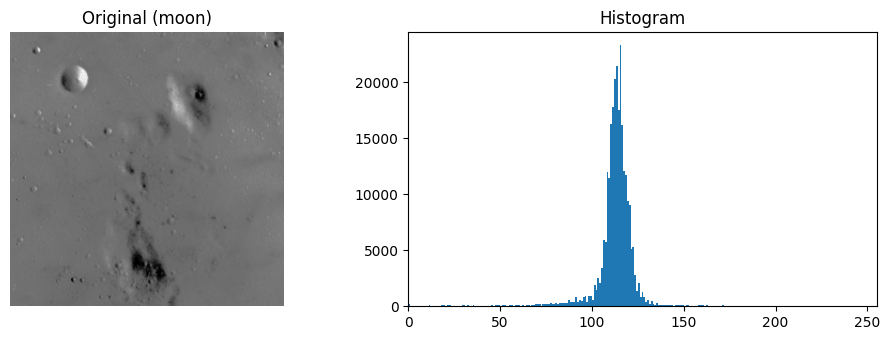

In [2]:
img = data.moon()          # 512x512 grayscale, uint8
print(img.shape, img.dtype, img.min(), img.max())

hist_cv = cv2.calcHist([img], [0], None, [256], [0, 256])
hist_np, _ = np.histogram(img.ravel(), bins=256, range=(0, 256))
print("Both methods agree:", np.array_equal(hist_cv.ravel().astype(int), hist_np))

show(img, 'Original (moon)')

**Observation:** The bars are spread across the full 0–255 range with more pixels on the dark side (the night sky) and a group of bright pixels (the moon and its glow). Because the histogram covers a wide range, the image is **well balanced (good contrast)** — the moon is bright and the landscape is dark, with no big empty gap in the middle.

## Task 2: Brightness and Contrast Analysis
Create three versions with different `alpha` (contrast) and `beta` (brightness) values using `cv2.convertScaleAbs`:  **output = alpha × input + beta**

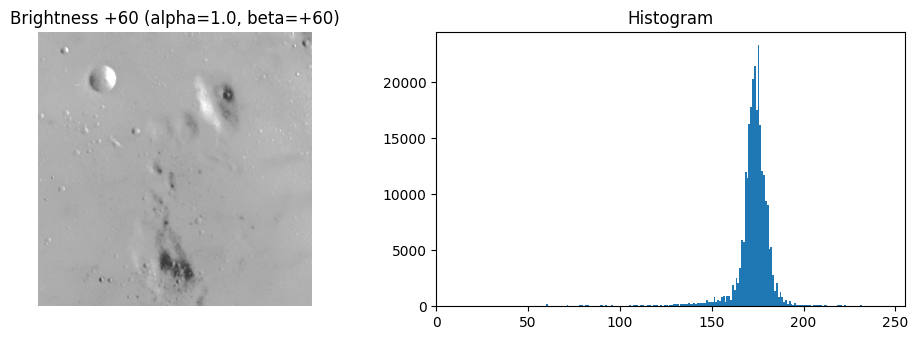

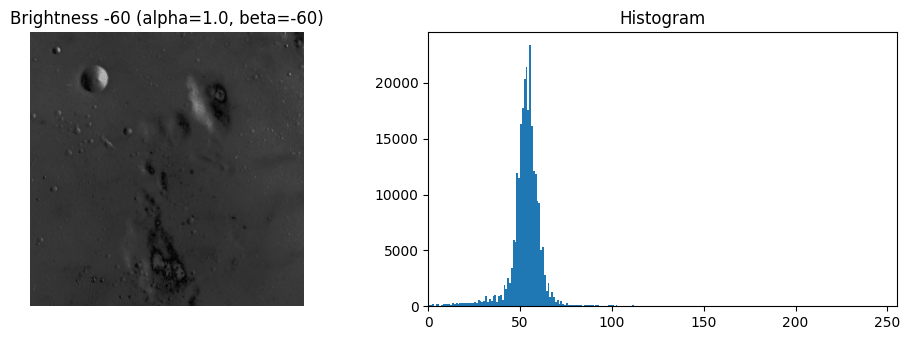

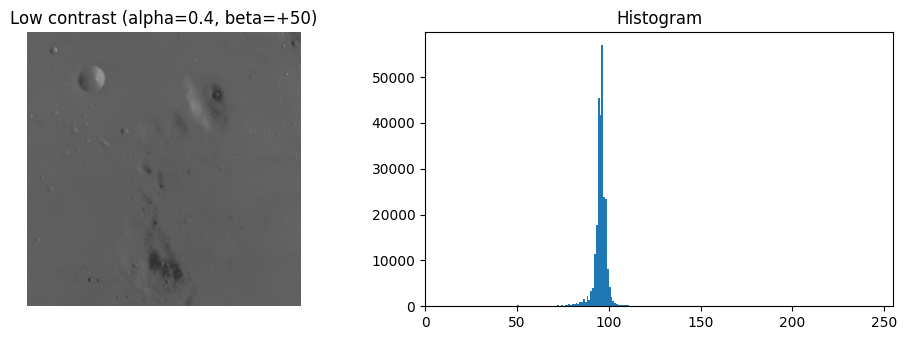

In [3]:
bright  = cv2.convertScaleAbs(img, alpha=1.0, beta=60)   # brightness +60
darker  = cv2.convertScaleAbs(img, alpha=1.0, beta=-60)  # brightness -60
low_con = cv2.convertScaleAbs(img, alpha=0.4, beta=50)   # low contrast

show(bright,  'Brightness +60 (alpha=1.0, beta=+60)')
show(darker,  'Brightness -60 (alpha=1.0, beta=-60)')
show(low_con, 'Low contrast (alpha=0.4, beta=+50)')

**Observations:**
- **Brightness +60:** the whole histogram **shifts to the right** by ~60; values above 255 are clipped at the right edge. Image looks washed out / too bright.
- **Brightness −60:** the whole histogram **shifts to the left**; many pixels pile up at 0. Image looks too dark.
- **Low contrast (alpha=0.4):** the histogram becomes **narrow** (squeezed around the middle) because values are pulled toward the mean. Image looks flat and gray.

## Task 3: Contrast Stretching (percentile-based)
Write our own `stretch(img, low_pct, high_pct)` function and compare (2, 98) with (0, 100).

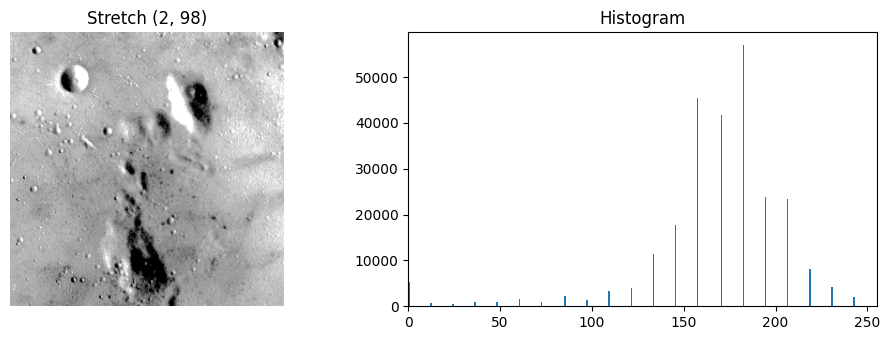

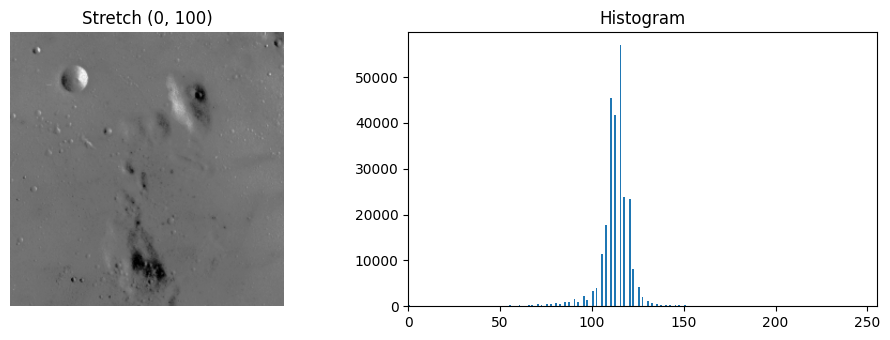

In [4]:
def stretch(img, low_pct, high_pct):
    lo, hi = np.percentile(img, (low_pct, high_pct))
    stretched = (img.astype(np.float32) - lo) * 255.0 / (hi - lo)
    return np.clip(stretched, 0, 255).astype(np.uint8)

stretch_2_98  = stretch(low_con, 2, 98)
stretch_0_100 = stretch(low_con, 0, 100)

show(stretch_2_98,  'Stretch (2, 98)')
show(stretch_0_100, 'Stretch (0, 100)')

**Comparison:**
- **(2, 98):** ignores the extreme 2% tails (outliers/noise), so the main histogram gets a strong stretch while a few outliers are clipped. Result: best contrast, fewest artifacts.
- **(0, 100):** uses the true min and max, so one stray bright/dark pixel limits the stretch — the histogram does not fill the full range and the image stays a little flatter. **(2, 98) looks more natural.**

## Task 4: Manual Histogram Equalization (no `cv2.equalizeHist`)
Equalization remaps each intensity through the **normalized CDF**:  s = (cdf(v) − cdf_min) / (N − cdf_min) × 255

Maximum absolute pixel difference vs OpenCV: 1


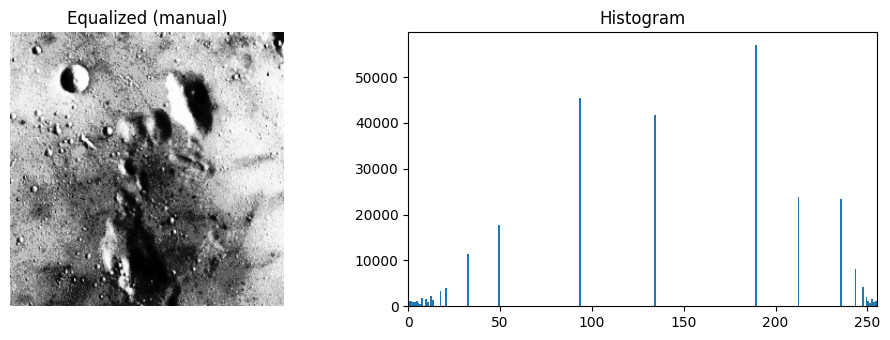

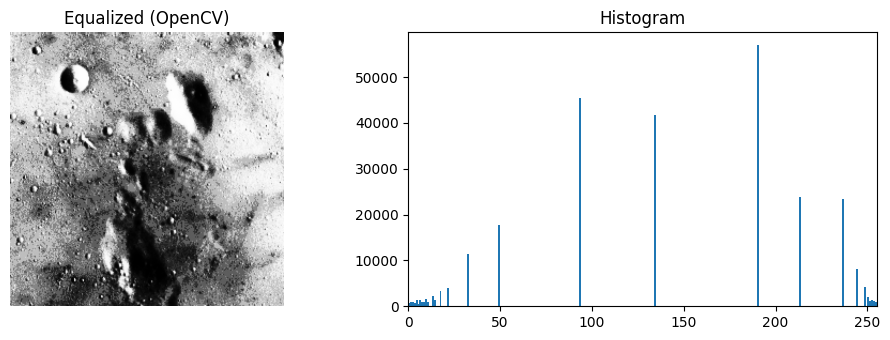

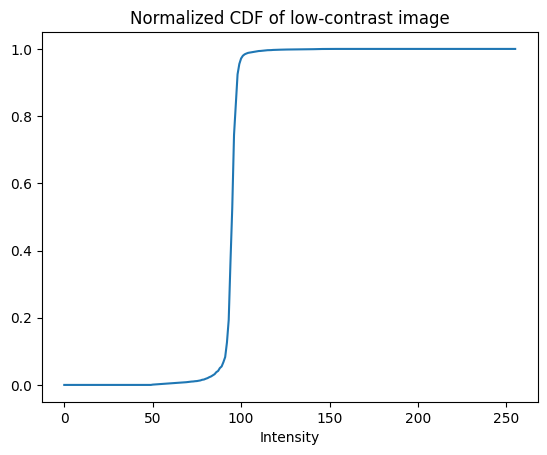

In [5]:
hist, _ = np.histogram(low_con.ravel(), 256, (0, 256))
cdf = hist.cumsum()
cdf_m = np.ma.masked_equal(cdf, 0)                    # mask zeros
cdf_m = (cdf_m - cdf_m.min()) * 255 / (cdf_m.max() - cdf_m.min())
lut = np.ma.filled(cdf_m, 0).astype(np.uint8)         # lookup table

manual_eq = lut[low_con]                              # apply mapping

eq_cv = cv2.equalizeHist(low_con)
max_diff = np.max(np.abs(manual_eq.astype(int) - eq_cv.astype(int)))
print("Maximum absolute pixel difference vs OpenCV:", max_diff)

show(manual_eq, 'Equalized (manual)')
show(eq_cv,     'Equalized (OpenCV)')

plt.plot(cdf / cdf.max()); plt.title('Normalized CDF of low-contrast image')
plt.xlabel('Intensity'); plt.show()

## Task 5: Global vs Adaptive Equalization (equalizeHist vs CLAHE)
Global equalization uses one mapping for the whole image; **CLAHE** equalizes small tiles separately and clips strong peaks to limit noise amplification.

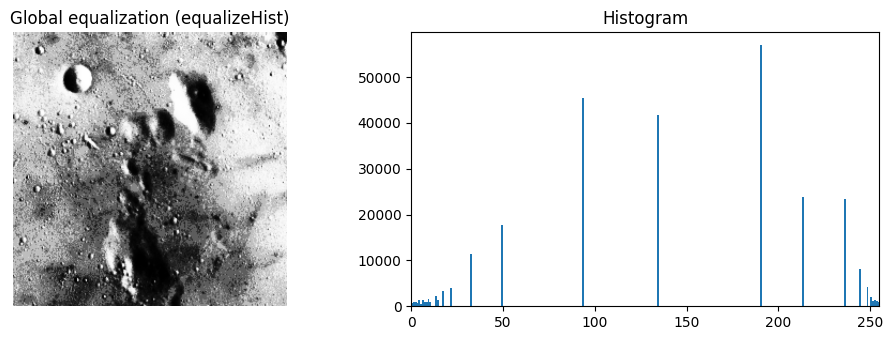

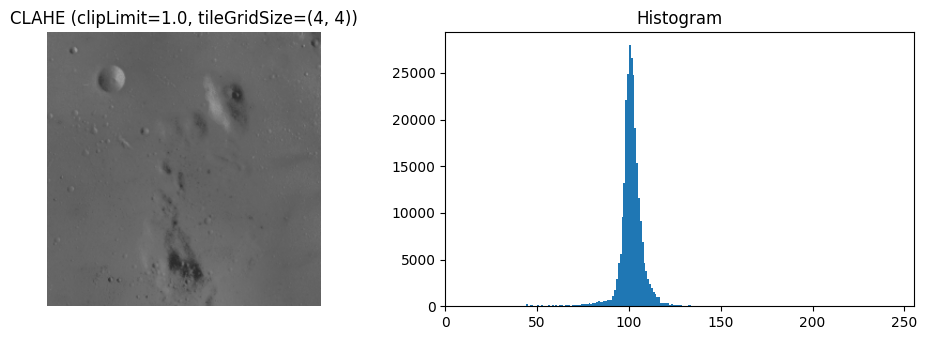

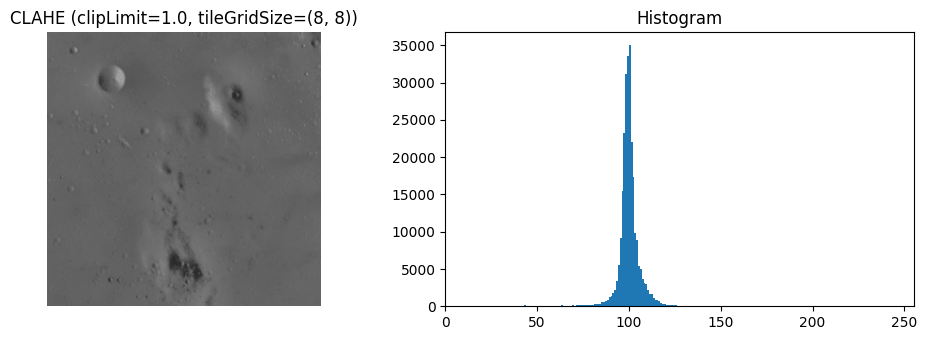

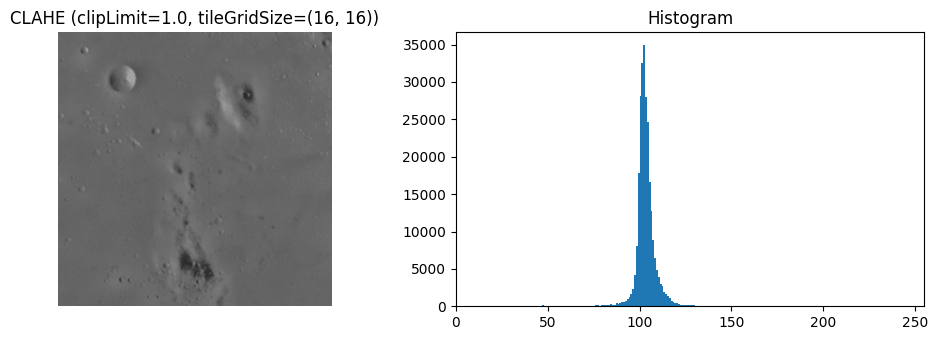

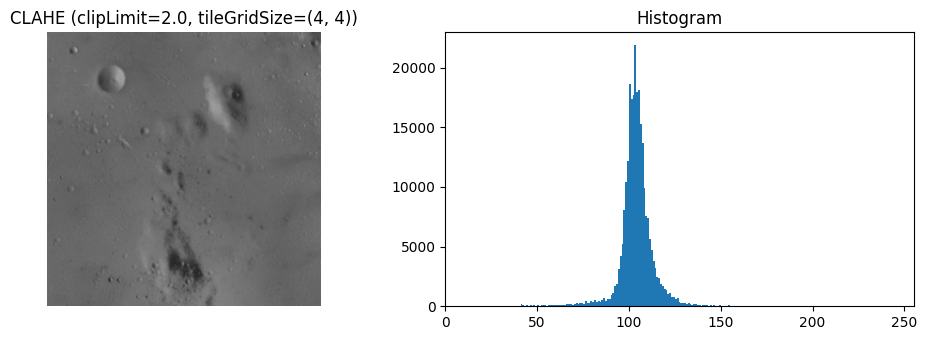

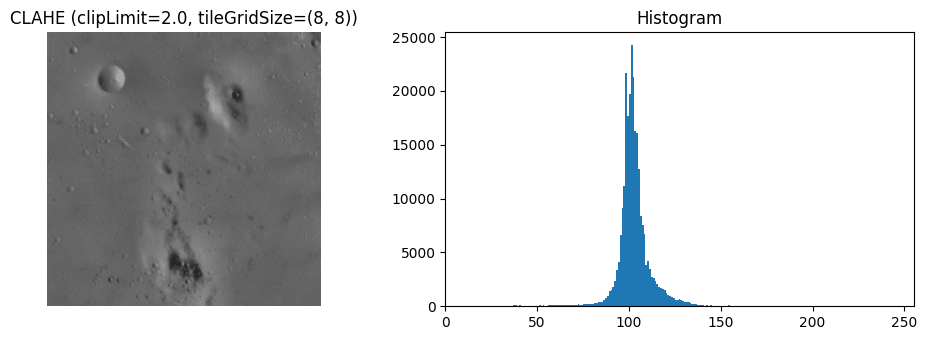

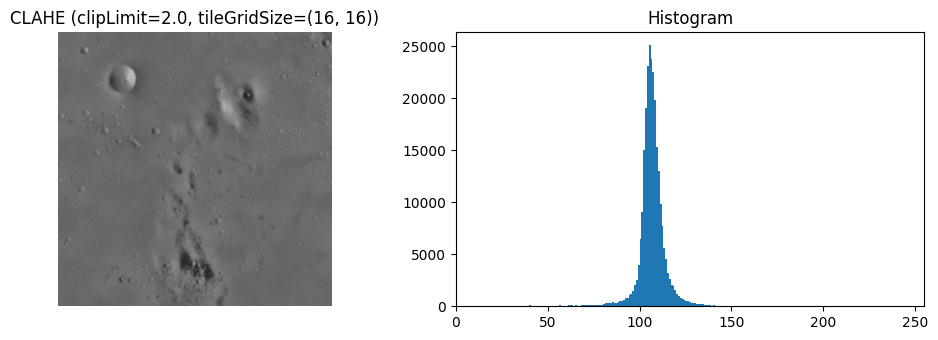

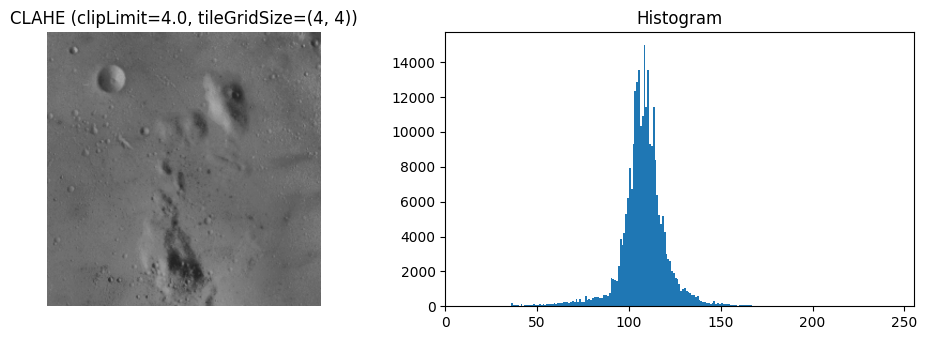

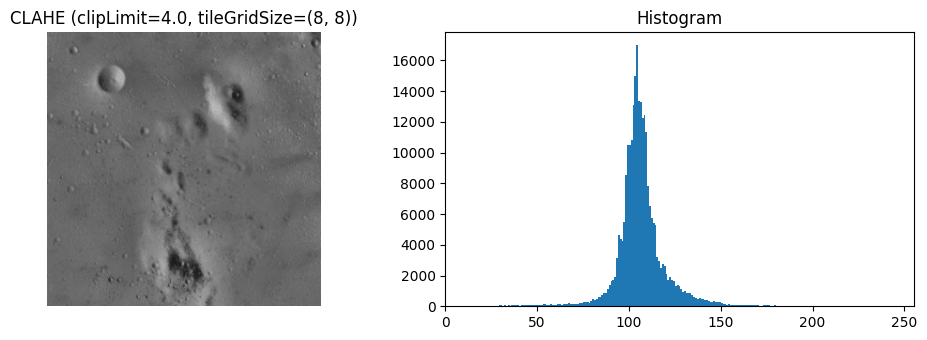

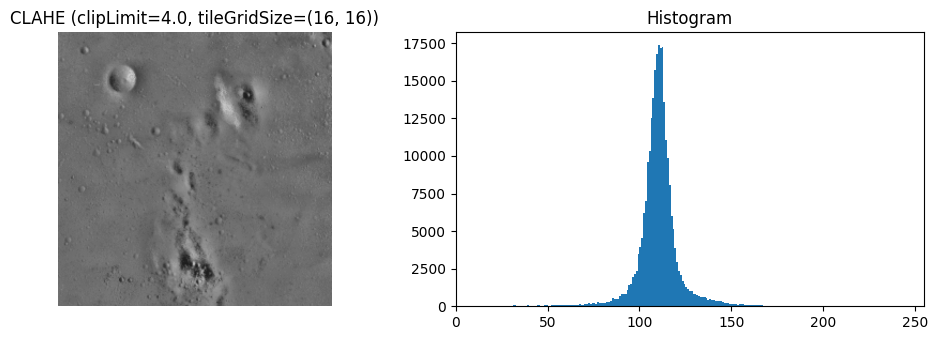

In [6]:
eq_global = cv2.equalizeHist(low_con)
show(eq_global, 'Global equalization (equalizeHist)')

clip_values = [1.0, 2.0, 4.0]
grid_values = [(4, 4), (8, 8), (16, 16)]

for clip in clip_values:
    for grid in grid_values:
        clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid)
        show(clahe.apply(low_con), f'CLAHE (clipLimit={clip}, tileGridSize={grid})')

## Task 6: Color Image Equalization (RGB channels vs Y channel)

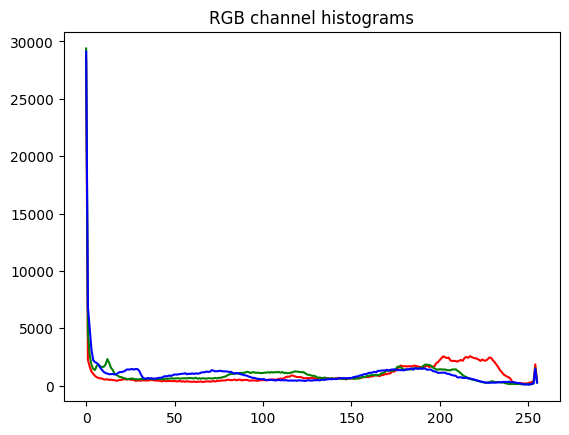

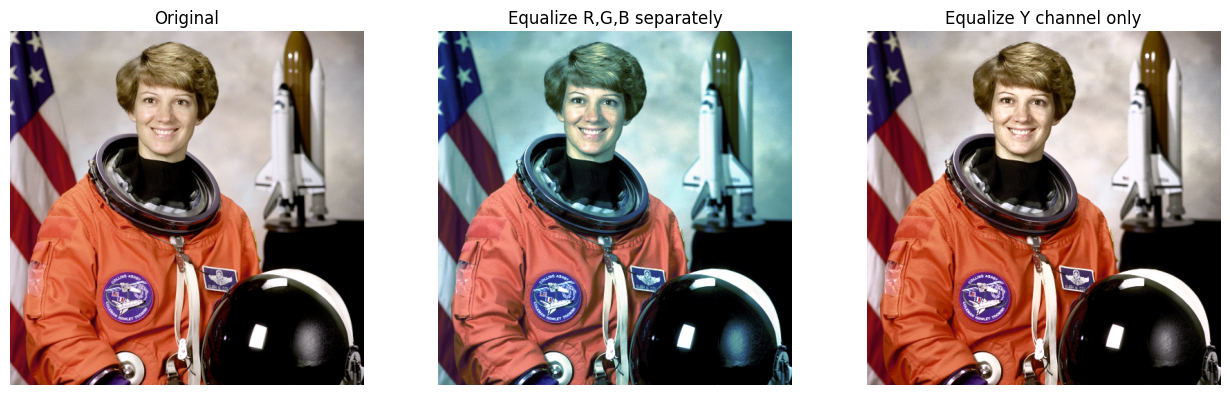

In [7]:
rgb = data.astronaut()

for i, c in enumerate(['r', 'g', 'b']):
    plt.plot(cv2.calcHist([rgb], [i], None, [256], [0, 256]), color=c)
plt.title('RGB channel histograms'); plt.show()

# (a) Equalize R, G, B separately
rgb_ch = rgb.copy()
for i in range(3):
    rgb_ch[:, :, i] = cv2.equalizeHist(rgb[:, :, i])

# (b) Equalize only the luminance (Y) channel
ycrcb = cv2.cvtColor(rgb, cv2.COLOR_RGB2YCrCb)
ycrcb[:, :, 0] = cv2.equalizeHist(ycrcb[:, :, 0])
rgb_eq = cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2RGB)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(rgb);     ax[0].set_title('Original');          ax[0].axis('off')
ax[1].imshow(rgb_ch);  ax[1].set_title('Equalize R,G,B separately'); ax[1].axis('off')
ax[2].imshow(rgb_eq);  ax[2].set_title('Equalize Y channel only');   ax[2].axis('off')
plt.tight_layout(); plt.show()